<a href="https://colab.research.google.com/github/redddddsu/Adaptative-SNN-Based-Triggering/blob/main/Software_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing API/Library


In [2]:
!pip install snntorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 882.6 kB/s eta 0:00:00


In [7]:
import torch
import snntorch as snn
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Dataset

In [51]:
import os

save_dir = "/content/drive/MyDrive/TUT_dataset"
os.makedirs(save_dir, exist_ok=True)

# !wget -c -O /content/tut_train_1.zip \
# "https://zenodo.org/records/401395/files/TUT-rare-sound-events-2017-development.mixture_data.1.zip?download=1"

# !unzip -l /content/tut_train_1.zip | head -25

# !wget -c -O /content/tut_source_events.zip \
# "https://zenodo.org/records/401395/files/TUT-rare-sound-events-2017-development.source_data_events.zip?download=1"

# !unzip -l /content/tut_source_events.zip | head -30

# !unzip -p /content/tut_source_events.zip \
# "TUT-rare-sound-events-2017-development/data/source_data/events/babycry/107351.yaml"

import zipfile
import os

zip_path = "/content/tut_source_events.zip"
output_dir = "/content/babycry_data"

with zipfile.ZipFile(zip_path) as z:
    babycry_files = [
        name for name in z.namelist()
        if "/events/babycry/" in name
        and name.endswith((".wav", ".yaml"))
    ]
    for name in babycry_files:
        z.extract(name, output_dir)

print("Extracted files:", len(babycry_files))
print("Saved under:", output_dir)

Extracted files: 68
Saved under: /content/babycry_data


In [48]:
import zipfile

zip_path = "/content/tut_mixture_1.zip"
extract_path = "/content/tut_mixture_1"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

FileNotFoundError: [Errno 2] No such file or directory: '/content/tut_mixture_1.zip'

Sample rate: 44100
Window samples: 2822
Hop samples: 1411
Mel spectrogram shape: (128, 938)
Log-mel shape: (128, 938)


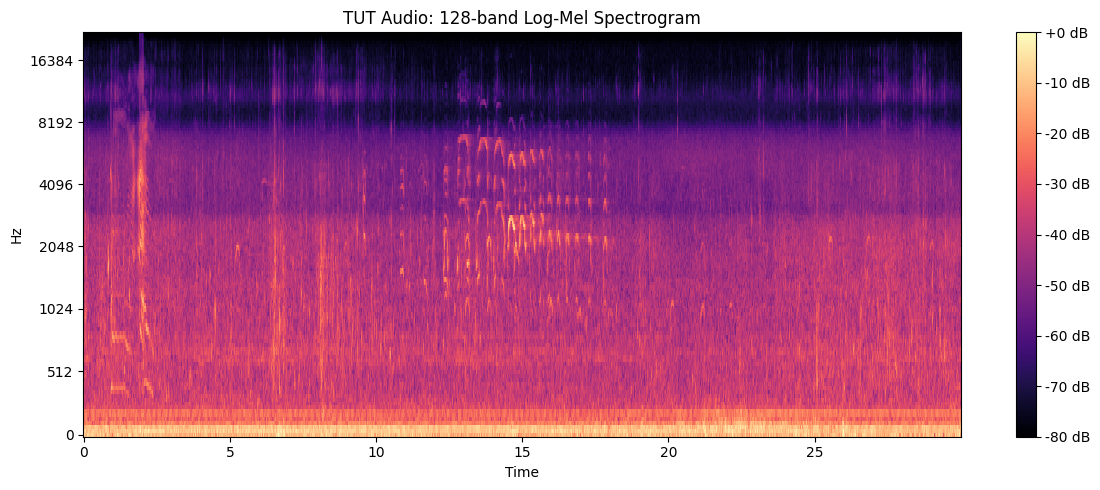

Feature vector shape: (128,)
First 10 feature values:
[-14.43308  -17.406433 -14.28983  -17.833149 -26.626953 -23.563053
 -24.044373 -28.492657 -29.602272 -30.242317]


In [23]:
import librosa
import numpy as np


# audio path
# /content/tut_mixture_1/TUT-rare-sound-events-2017-development/data/mixture_data/devtest/20b255387a2d0cddc0a3dff5014875e7/audio

audio_path = "/content/tut_mixture_1/TUT-rare-sound-events-2017-development/data/mixture_data/devtest/20b255387a2d0cddc0a3dff5014875e7/audio"


# Implementation

In [5]:
# u_new = (new input)(leak) + u_old
# if the neuron accumalates to over 1 threshold, fire a spike

threshold = 1.0
potential = 0
leak = 0.9
input_test = torch.tensor(0.6)
weight = 1.5

neuron_a = snn.Leaky(beta=leak, threshold=threshold, reset_mechanism="zero")
neuron_b = snn.Leaky(beta=leak, threshold=threshold, reset_mechanism="zero")

mem_a = neuron_a.init_leaky()
mem_b = neuron_b.init_leaky()

for i in range(10):

  spike_a, mem_a = neuron_a(input_test, mem_a)
  input_b = spike_a * weight
  spike_b, mem_b = neuron_b(input_b, mem_b)

  print("Spike A: ", spike_a)
  print("Mem A: ", mem_a)
  print("Spike B: ", spike_b)
  print("Mem B: ", mem_b)


Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
Spike A:  tensor(0.)
Mem A:  tensor(0.6000)
Spike B:  tensor(0.)
Mem B:  tensor(0.)
Spike A:  tensor(1.)
Mem A:  tensor(1.1400)
Spike B:  tensor(1.)
Mem B:  tensor(1.5000)
